In [3]:
import sys
import os
import json
import numpy as np
import scipy as sp

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../mouse-control/src'))
from utils_mouse_control import read_utils as read_utils_control

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils
from utils import ai_slob

In [4]:
import importlib
importlib.reload(read_utils)
importlib.reload(read_utils_control)
importlib.reload(analysis_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [9]:
# file_ids = list(range(0, 12+1))
file_ids = [2]

organism = 'mouse'
model_variant = 'ns'

In [10]:
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
filenames = [read_utils.get_filename(read_utils.get_filepath(path, file_id)) for file_id in file_ids]

# scores

In [11]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [14]:
scores_per_shuffle = list()
for shuffle_id in range(100):
	scores_per_dataset = list()
	for filename in filenames:
		((bom_spn, _, _, _, _, _, _),
		 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(read_utils_control.get_model_path(shuffle_id), filename, model_variant, manual=False)
		scores_per_dataset.append((bom_spn, hgm_spn))
	bom_spns, hgm_spns = zip(*scores_per_dataset)
	scores_per_shuffle.append([bom_spns, hgm_spns])

neuron_scores_per_shuffle = [assemble(*scores_per_shuffle[i]) for i in range(100)]
scores_per_shuffle = None

In [15]:
scores_per_dataset_actual = list()
for filename in filenames:
	((bom_spn, _, _, _, _, _, _),
	 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(read_utils.get_model_path(), filename, model_variant, manual=False)
	scores_per_dataset_actual.append((bom_spn, hgm_spn))
bom_spns_actual, hgm_spns_actual = zip(*scores_per_dataset_actual)

neuron_scores_actual = assemble(bom_spns_actual, hgm_spns_actual)
scores_per_dataset_actual = None

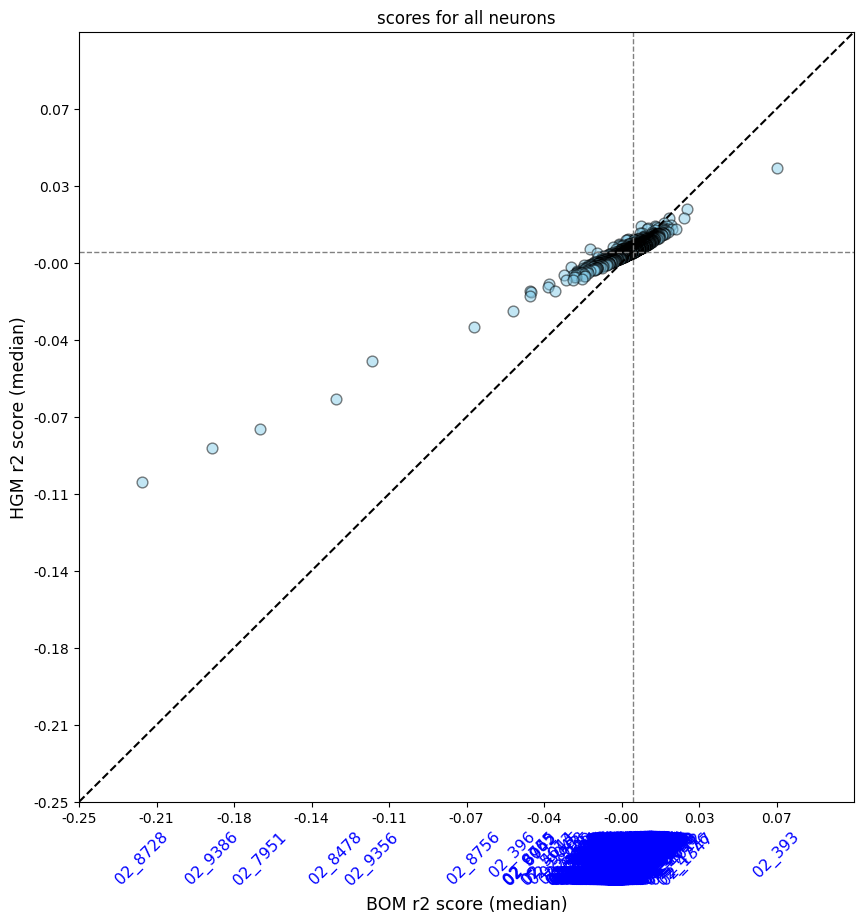

In [16]:
plot_utils.plot_performance_plot(
	neuron_scores_actual, None,
	title='scores for all neurons', limits=(-0.25, 0.1, -0.25, 0.1), force_medians=False
)

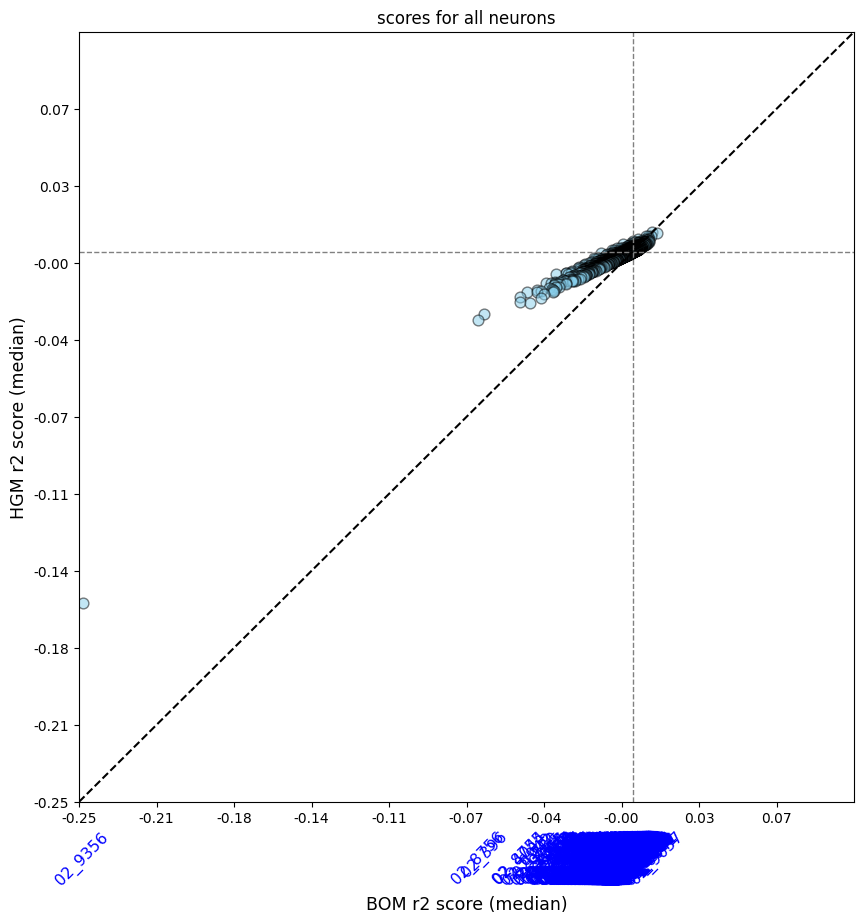

In [17]:
plot_utils.plot_performance_plot(
	neuron_scores_per_shuffle[0], None,
	title='scores for all neurons', limits=(-0.25, 0.1, -0.25, 0.1), force_medians=False
)

In [23]:
neuron_scores_per_shuffle_merged = ai_slob.merge_neuron_scores_per_shuffle(neuron_scores_per_shuffle)

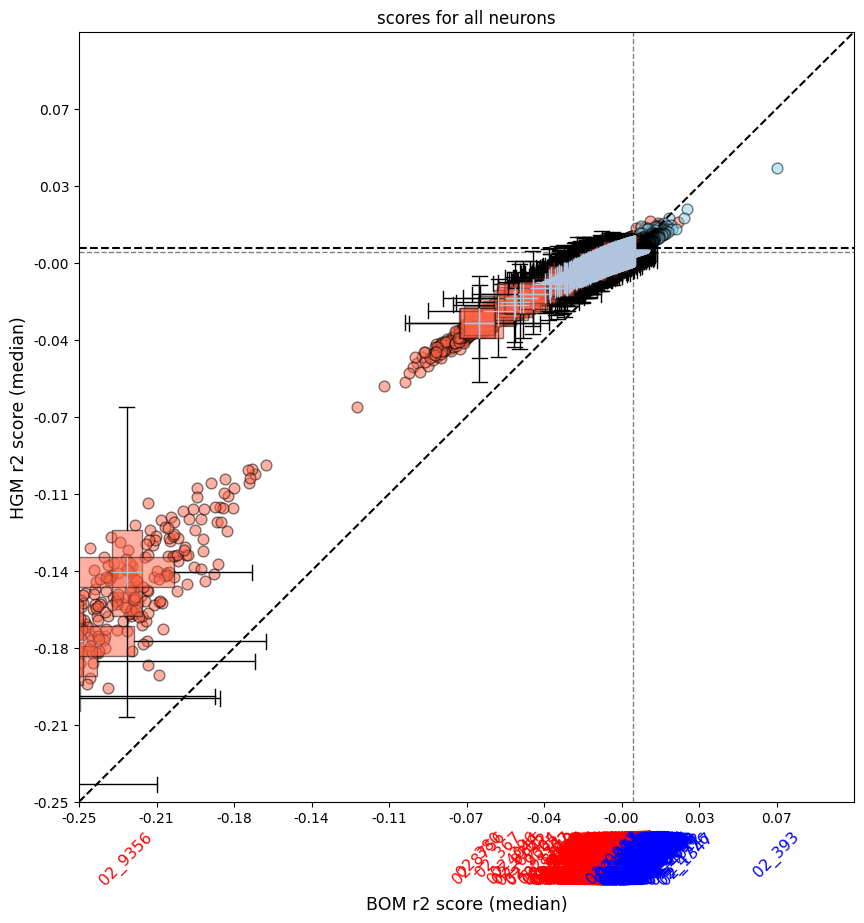

In [24]:
plot_utils.plot_performance_plot(
	neuron_scores_actual, neuron_scores_per_shuffle_merged,
	title='scores for all neurons', limits=(-0.25, 0.1, -0.25, 0.1), force_medians=False
)

In [11]:
# compute HGM percentiles (default agg: mean of flattened array)
percentiles_hgm = ai_slob.compute_neuron_percentiles(
    neuron_scores_actual,
    neuron_scores_per_shuffle,
    model='hgm'
)

# compute BOM percentiles
percentiles_bom = ai_slob.compute_neuron_percentiles(
    neuron_scores_actual,
    neuron_scores_per_shuffle,
    model='bom'
)

# print top 10 neurons by HGM percentile
top10 = sorted(percentiles_hgm.items(), key=lambda kv: kv[1] if not np.isnan(kv[1]) else -1, reverse=True)[:]
for label, pct in top10:
    print(f"{label}: {pct:.1f} percentile")

02_393: 100.0 percentile
02_1347: 100.0 percentile
02_8040: 100.0 percentile
02_4776: 100.0 percentile
02_2844: 100.0 percentile
02_4043: 100.0 percentile
02_1896: 100.0 percentile
02_3712: 100.0 percentile
02_1364: 100.0 percentile
02_2566: 100.0 percentile
02_2856: 100.0 percentile
02_1348: 100.0 percentile
02_2314: 100.0 percentile
02_048: 100.0 percentile
02_8883: 100.0 percentile
02_2659: 100.0 percentile
02_6242: 100.0 percentile
02_4012: 100.0 percentile
02_5000: 100.0 percentile
02_9082: 100.0 percentile
02_9037: 100.0 percentile
02_4028: 100.0 percentile
02_041: 100.0 percentile
02_9242: 100.0 percentile
02_5277: 100.0 percentile
02_1337: 100.0 percentile
02_7287: 100.0 percentile
02_5249: 100.0 percentile
02_034: 100.0 percentile
02_9235: 100.0 percentile
02_7792: 100.0 percentile
02_3845: 100.0 percentile
02_6635: 100.0 percentile
02_5464: 100.0 percentile
02_100: 100.0 percentile
02_2005: 100.0 percentile
02_2217: 100.0 percentile
02_9107: 100.0 percentile
02_044: 100.0 per

In [ ]:
# Example usage: plots the top-10 neurons by actual HGM score
chosen = ai_slob.plot_first_n_neurons(neuron_scores_actual, neuron_scores_per_shuffle, model='hgm', n=10)
print("Plotted neurons:", chosen)

# If you want the literal insertion-order 'first 10 keys' instead, call:
# first10_insertion_order = list(neuron_scores_actual.keys())[:10]
# chosen = plot_first_n_neurons(neuron_scores_actual, neuron_scores_per_shuffle, model='hgm', neuron_labels=first10_insertion_order)